In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
df = pd.read_csv('customer_churn_data_raw.csv')
df 

,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,4/12/1982,travel,NaN
1,0003-MKNFE,raghav,India,Karnataka,Male,11/23/1995,NaN,NaN
2,0004-TLHLJ,lalita,India,Delhi,Female,2/15/1978,movie,NaN
3,0011-IGKFF,mohan,India,Nagaland,Male,8/30/2001,NaN,NaN
4,0013-EXCHZ,mira,India,Delhi,Female,5/5/1990,drama,NaN
5,0013-MHZWF,durga,NaN,Delhi,Women,12/10/1988,NaN,NaN
6,0013-SMEOE,mina,India,Meghalaya,Female,9/21/1976,NaN,NaN
7,0014-BMAQU,madan,India,Rajasthan,Male,3/14/1999,NaN,NaN
8,0015-UOCOJ,maya,NaN,Kathmandu,Women,7/7/1985,NaN,NaN
9,0016-QLJIS,arjun,Nepal,Kathmandu,Male,10/29/1993,NaN,NaN


In [3]:
df_clean = df.copy()

In [4]:
df_clean

,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,4/12/1982,travel,NaN
1,0003-MKNFE,raghav,India,Karnataka,Male,11/23/1995,NaN,NaN
2,0004-TLHLJ,lalita,India,Delhi,Female,2/15/1978,movie,NaN
3,0011-IGKFF,mohan,India,Nagaland,Male,8/30/2001,NaN,NaN
4,0013-EXCHZ,mira,India,Delhi,Female,5/5/1990,drama,NaN
5,0013-MHZWF,durga,NaN,Delhi,Women,12/10/1988,NaN,NaN
6,0013-SMEOE,mina,India,Meghalaya,Female,9/21/1976,NaN,NaN
7,0014-BMAQU,madan,India,Rajasthan,Male,3/14/1999,NaN,NaN
8,0015-UOCOJ,maya,NaN,Kathmandu,Women,7/7/1985,NaN,NaN
9,0016-QLJIS,arjun,Nepal,Kathmandu,Male,10/29/1993,NaN,NaN


In [5]:
#removing unnecessary columns from dataset 
df_clean.drop(labels=['pincode','interests'],axis = 1,inplace=True)

In [6]:
#checking weather customerid is uniqaue or not 
# df_clean['customerid'].count()
df_clean['customerid'].unique()



<ArrowStringArray>
['0002-ORFBO', '0003-MKNFE', '0004-TLHLJ', '0011-IGKFF', '0013-EXCHZ',
 '0013-MHZWF', '0013-SMEOE', '0014-BMAQU', '0015-UOCOJ', '0016-QLJIS',
 '0017-DINOC', '0017-IUDMW', '0018-NYROU', '0019-EFAEP', '0019-GFNTW',
 '0020-INWCK', '0020-JDNXP', '0021-IKXGC', '0022-TCJCI', '0023-HGHWL',
 '0023-UYUPN',          nan]
Length: 22, dtype: str

In [7]:
df_clean = df.dropna(subset=['customerid'])

In [8]:
df_clean

,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,4/12/1982,travel,NaN
1,0003-MKNFE,raghav,India,Karnataka,Male,11/23/1995,NaN,NaN
2,0004-TLHLJ,lalita,India,Delhi,Female,2/15/1978,movie,NaN
3,0011-IGKFF,mohan,India,Nagaland,Male,8/30/2001,NaN,NaN
4,0013-EXCHZ,mira,India,Delhi,Female,5/5/1990,drama,NaN
5,0013-MHZWF,durga,NaN,Delhi,Women,12/10/1988,NaN,NaN
6,0013-SMEOE,mina,India,Meghalaya,Female,9/21/1976,NaN,NaN
7,0014-BMAQU,madan,India,Rajasthan,Male,3/14/1999,NaN,NaN
8,0015-UOCOJ,maya,NaN,Kathmandu,Women,7/7/1985,NaN,NaN
9,0016-QLJIS,arjun,Nepal,Kathmandu,Male,10/29/1993,NaN,NaN


In [9]:
df_clean.dropna(subset='gender',inplace=True)

In [10]:
# 1. Standardize both 'Men' -> 'Male' and 'Women' -> 'Female'
df_clean['gender'] = df_clean['gender'].replace({'Men': 'Male', 'Women': 'Female'})


# 2. Check unique values on the same dataframe
print(df_clean['gender'].unique())

<ArrowStringArray>
['Male', 'Female']
Length: 2, dtype: str


In [11]:
df_clean['country'].unique()

<ArrowStringArray>
['India', nan, 'Nepal']
Length: 3, dtype: str

In [12]:
#cleaning state-country relation 
# Groups by state, and propagates non-null countries within each state
df_clean['country'] = df_clean.groupby('state')['country'].transform(lambda s: s.ffill().bfill()) 

In [13]:
df_clean


,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,4/12/1982,travel,NaN
1,0003-MKNFE,raghav,India,Karnataka,Male,11/23/1995,NaN,NaN
2,0004-TLHLJ,lalita,India,Delhi,Female,2/15/1978,movie,NaN
3,0011-IGKFF,mohan,India,Nagaland,Male,8/30/2001,NaN,NaN
4,0013-EXCHZ,mira,India,Delhi,Female,5/5/1990,drama,NaN
5,0013-MHZWF,durga,India,Delhi,Female,12/10/1988,NaN,NaN
6,0013-SMEOE,mina,India,Meghalaya,Female,9/21/1976,NaN,NaN
7,0014-BMAQU,madan,India,Rajasthan,Male,3/14/1999,NaN,NaN
8,0015-UOCOJ,maya,Nepal,Kathmandu,Female,7/7/1985,NaN,NaN
9,0016-QLJIS,arjun,Nepal,Kathmandu,Male,10/29/1993,NaN,NaN


In [14]:
#cleaning date of birth converting datatype from string to datetime 
df_clean['dob'] = pd.to_datetime(df_clean['dob'], errors='coerce')
df_clean['dob'].dtype

dtype('<M8[us]')

In [15]:
#checking weather everything is perfect in state column 

df_clean['state'].value_counts()


state
Delhi            4
Maharashtra      3
Meghalaya        3
Karnataka        2
Rajasthan        2
Kathmandu        2
Telangana        2
Uttar Pradesh    2
Nagaland         1
Name: count, dtype: int64

In [16]:
df_clean['state'].unique()

<ArrowStringArray>
[  'Maharashtra',     'Karnataka',         'Delhi',      'Nagaland',
     'Meghalaya',     'Rajasthan',     'Kathmandu',     'Telangana',
 'Uttar Pradesh']
Length: 9, dtype: str

In [17]:
# Load the other two sheets from your original Excel file
df_db_subscription = pd.read_excel(
    'customer_churn_data_raw.xlsx', sheet_name='db_subscription'
)
df_db_support = pd.read_excel(
    'customer_churn_data_raw.xlsx', sheet_name='db_support'
)

In [18]:
df_db_subscription_clean = df_db_subscription
df_db_support_clean = df_db_support

In [19]:
df_db_subscription_clean['plan_type'].unique()

<ArrowStringArray>
['Standard', 'Premium', 'Basic']
Length: 3, dtype: str

In [20]:
# 1. Convert subscription dates to datetime
date_cols = ['subscription_start_date', 'renewal_date', 'cancellation_date']
df_db_subscription_clean[date_cols] = df_db_subscription_clean[date_cols].apply(
    pd.to_datetime
)

In [21]:
df_db_subscription_clean

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88
5,0013-MHZWF,2022-06-18,Paid,2025-06-18,Standard,Annual,NaT,NaN,17.99,720,22
6,0013-SMEOE,2021-09-30,Refferal,2024-09-30,Basic,Monthly,2024-11-15,Not enough content,8.99,230,79
7,0014-BMAQU,2020-02-14,Organic,2025-02-14,Premium,Annual,NaT,NaN,22.99,1840,5
8,0015-UOCOJ,2023-07-22,Organic,2024-07-22,Standard,Monthly,NaT,NaN,13.99,240,34
9,0016-QLJIS,2022-04-03,Organic,2025-04-03,Basic,Annual,NaT,NaN,6.99,335,41


In [22]:
df_db_subscription_clean['subscription_type'].unique()

<ArrowStringArray>
['Refferal', 'Paid', 'Organic']
Length: 3, dtype: str

In [23]:
# 2. Create the target churn flag (1 if cancelled, 0 if active)
df_db_subscription_clean['churn_flag'] = np.where(
    df_db_subscription_clean['cancellation_date'].notna(), 1, 0
)

In [24]:
# 3. Clean the support table
df_db_support_clean.drop(
    columns=['col_1', 'comment'], inplace=True, errors='ignore'
)
df_db_support_clean['complaint_date'] = pd.to_datetime(
    df_db_support_clean['complaint_date']
)

In [25]:
# Count total complaints per customer
df_db_support_clean['complaint_count'] = df_db_support_clean.groupby('customerid')[
    'customerid'
].transform('count')

# Keep the latest complaint record per customer so customerid stays unique (1:1 join)
df_db_support_unique = df_db_support_clean.sort_values(
    'complaint_date'
).drop_duplicates('customerid', keep='last')

In [26]:
#meging joining all tales on customer_id 
df_merged = df_db_subscription_clean.merge(
    df_clean, on='customerid', how='left'
).merge(df_db_support_unique, on='customerid', how='left')

print("Merged Shape:", df_merged.shape)  # Should be (21, 21)

Merged Shape: (21, 23)


In [27]:
df_db_support_unique

,customerid,complaint_date,escalations,csat_score,complaint_count
2,0013-EXCHZ,2024-01-20,Y,20,1
5,0017-IUDMW,2024-04-10,Y,25,1
1,0003-MKNFE,2024-08-28,Y,10,2
8,0022-TCJCI,2024-09-14,N,90,2
6,0019-EFAEP,2024-09-27,Y,30,1
4,0013-SMEOE,2024-11-01,N,30,1
3,0013-MHZWF,2025-03-18,N,90,1


In [28]:
df_merged

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,country,state,gender,dob,interests,pincode,complaint_date,escalations,csat_score,complaint_count
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,...,India,Maharashtra,Male,1982-04-12,travel,NaN,NaT,NaN,NaN,NaN
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,India,Karnataka,Male,1995-11-23,NaN,NaN,2024-08-28,Y,10.0,2.0
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,...,India,Delhi,Female,1978-02-15,movie,NaN,NaT,NaN,NaN,NaN
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,...,India,Nagaland,Male,2001-08-30,NaN,NaN,NaT,NaN,NaN,NaN
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,...,India,Delhi,Female,1990-05-05,drama,NaN,2024-01-20,Y,20.0,1.0
5,0013-MHZWF,2022-06-18,Paid,2025-06-18,Standard,Annual,NaT,NaN,17.99,720,...,India,Delhi,Female,1988-12-10,NaN,NaN,2025-03-18,N,90.0,1.0
6,0013-SMEOE,2021-09-30,Refferal,2024-09-30,Basic,Monthly,2024-11-15,Not enough content,8.99,230,...,India,Meghalaya,Female,1976-09-21,NaN,NaN,2024-11-01,N,30.0,1.0
7,0014-BMAQU,2020-02-14,Organic,2025-02-14,Premium,Annual,NaT,NaN,22.99,1840,...,India,Rajasthan,Male,1999-03-14,NaN,NaN,NaT,NaN,NaN,NaN
8,0015-UOCOJ,2023-07-22,Organic,2024-07-22,Standard,Monthly,NaT,NaN,13.99,240,...,Nepal,Kathmandu,Female,1985-07-07,NaN,NaN,NaT,NaN,NaN,NaN
9,0016-QLJIS,2022-04-03,Organic,2025-04-03,Basic,Annual,NaT,NaN,6.99,335,...,Nepal,Kathmandu,Male,1993-10-29,NaN,NaN,NaT,NaN,NaN,NaN


In [29]:
#calculating churn rate 
churn_rate = df_merged['churn_flag'].mean() * 100.0
retention_rate = 100.0 - churn_rate

print(f"Percentage of total customers leaving our platform: {churn_rate:.1f}%")
print(f"Percentage of total customers staying with our platform: {retention_rate:.1f}%")

Percentage of total customers leaving our platform: 28.6%
Percentage of total customers staying with our platform: 71.4%


In [30]:
# 2. Churn Rate by Plan Type
churn_by_plan = (
   df_merged.groupby('plan_type')['churn_flag']
    .mean()
    .mul(100)
    .round(2)
    .reset_index(name='churn_rate_pct')
)
print('\nChurn by Plan:\n', churn_by_plan)


Churn by Plan:
   plan_type  churn_rate_pct
0     Basic           60.00
1   Premium           14.29
2  Standard           22.22


In [31]:
df_merged.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'name', 'country', 'state', 'gender', 'dob', 'interests',
       'pincode', 'complaint_date', 'escalations', 'csat_score',
       'complaint_count'],
      dtype='str')

In [32]:
# 3. Average Revenue Per User (ARPU)
arpu = df_merged['monthly_charges'].mean()
print(f'\nARPU: ${arpu:.2f}')


ARPU: $18.85


In [33]:
#revenue at risk for organisations 
revenue_at_risk = df_merged.loc[
        df_merged['churn_flag'] == 1,'monthly_charges'
    ].sum() 
print(f"Revenue at risk : ${revenue_at_risk : .1f}")

Revenue at risk : $ 73.9


In [34]:
# 5. Escalation Rate & Correlation to Churn
escalation_rate = (df_merged['escalations'] == 'Y').mean() * 100
print(f'Escalation Rate: {escalation_rate:.2f}%') 

Escalation Rate: 19.05%


In [35]:
#Now let's find correlation between escalation and churn 
# for correlation we need to convert escalation to numeric 
df_merged['escalations_num'] = np.where(df_merged['escalations'] == 'Y' ,1,0)
corr_val = df_merged['escalations_num'].corr(df_merged['churn_flag'])
print(f'Correlation between Escalations and Churn: {corr_val:.2f}')

Correlation between Escalations and Churn: 0.77


In [36]:

#Categorising churn score as churn risk 
conditions = [
    (df_merged['churn_score'] < 50),
    (df_merged['churn_score'] >= 50) & (df_merged['churn_score'] < 70),
    (df_merged['churn_score'] >= 70),
]
choices = ['low', 'med', 'high']
df_merged['churn_risk'] = np.select(conditions, choices, default='unknown')
df_merged['churn_risk']

0      low
1     high
2      low
3      low
4     high
5      low
6     high
7      low
8      low
9      low
10     low
11    high
12     low
13    high
14     low
15     med
16     med
17     low
18    high
19     low
20     low
Name: churn_risk, dtype: str

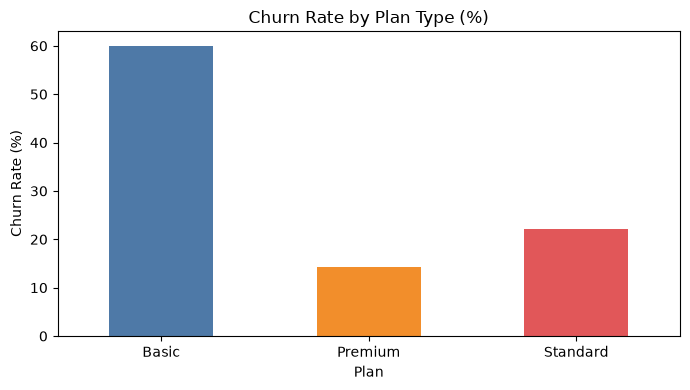

In [37]:
#Here comes visualization part 
# 1. Bar Chart: Churn Rate by Plan 
plt.figure(figsize=(7, 4))
plan_churn = df_merged.groupby('plan_type')['churn_flag'].mean() * 100
plan_churn.plot(kind='bar', color=['#4e79a7', '#f28e2b', '#e15759'])
plt.title('Churn Rate by Plan Type (%)')
plt.ylabel('Churn Rate (%)')
plt.xlabel('Plan')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

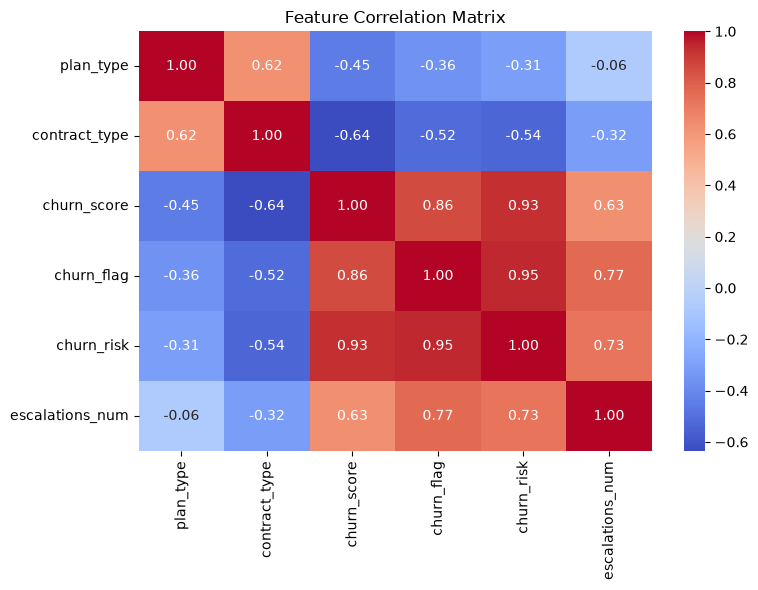

In [38]:
# 2. Priority-Ordered Heatmap
df_encoded = df_merged[
    [
        'plan_type',
        'contract_type',
        'churn_score',
        'churn_flag',
        'churn_risk',
        'escalations_num',
    ]
].copy()

order_mappings = {
    'plan_type': ['Basic', 'Standard', 'Premium'],
    'contract_type': ['Monthly', 'Annual'],
    'churn_risk': ['low', 'med', 'high'],
}

for col, order in order_mappings.items():
  df_encoded[col] = pd.Categorical(
      df_encoded[col].astype('category'), categories=order, ordered=True
  ).codes

plt.figure(figsize=(8, 6))
sns.heatmap(df_encoded.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation Matrix')
plt.tight_layout()
plt.show()

In [39]:
df_merged

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,gender,dob,interests,pincode,complaint_date,escalations,csat_score,complaint_count,escalations_num,churn_risk
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,...,Male,1982-04-12,travel,NaN,NaT,NaN,NaN,NaN,0,low
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,Male,1995-11-23,NaN,NaN,2024-08-28,Y,10.0,2.0,1,high
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,...,Female,1978-02-15,movie,NaN,NaT,NaN,NaN,NaN,0,low
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,...,Male,2001-08-30,NaN,NaN,NaT,NaN,NaN,NaN,0,low
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,...,Female,1990-05-05,drama,NaN,2024-01-20,Y,20.0,1.0,1,high
5,0013-MHZWF,2022-06-18,Paid,2025-06-18,Standard,Annual,NaT,NaN,17.99,720,...,Female,1988-12-10,NaN,NaN,2025-03-18,N,90.0,1.0,0,low
6,0013-SMEOE,2021-09-30,Refferal,2024-09-30,Basic,Monthly,2024-11-15,Not enough content,8.99,230,...,Female,1976-09-21,NaN,NaN,2024-11-01,N,30.0,1.0,0,high
7,0014-BMAQU,2020-02-14,Organic,2025-02-14,Premium,Annual,NaT,NaN,22.99,1840,...,Male,1999-03-14,NaN,NaN,NaT,NaN,NaN,NaN,0,low
8,0015-UOCOJ,2023-07-22,Organic,2024-07-22,Standard,Monthly,NaT,NaN,13.99,240,...,Female,1985-07-07,NaN,NaN,NaT,NaN,NaN,NaN,0,low
9,0016-QLJIS,2022-04-03,Organic,2025-04-03,Basic,Annual,NaT,NaN,6.99,335,...,Male,1993-10-29,NaN,NaN,NaT,NaN,NaN,NaN,0,low


In [40]:
df_merged.to_excel('Merged.xlsx')